## 1. The Ramsey Model Using Python for well-being analysis

##### **By: Daniel Ricardo Amaya Alba, M.S. in Political Science from Los Andes University and Master's Student in Economics at Javeriana University**

### Why we need a new model

In the first session we built the Solow model, simulated it, found its steady state three different ways, and drew its diagram. We ended with a question that we did not answer.

We drew a curve, $s\,f(k)$, and called it investment. But that curve is a **decision rule**: it says how much this economy sets aside for tomorrow at every level of capital it might have today. And we simply invented it setting son value $s = 0.25$ 

That is a serious limitation, and not only a theoretical one. Suppose the government asks us: *should Colombia save more?* Solow cannot answer. It can tell us that a higher $s$ produces a higher steady-state capital stock, but it has no way of saying whether the people living in that economy would be **better off**. There is nobody in the model whose well-being we could measure.


### What a well-being analysis is

The Ramsey model adds one thing to Solow: a household that **chooses** consumption to maximize its own welfare. Once we have that household, we can do something Solow never allowed:

> Take two economic policies, compute the consumption path each one produces, and ask which one the household prefers — **and by how much**.



### How this guide is organized

This guide covers two sessions of the complementary class.

- **Part I (Session 2), sections 2 to 11.** We build a measure of well-being, use it on the Solow model, derive the Euler equation in both clocks, find the steady state, draw the phase diagram and solve the model with the **shooting method**. We close with the problem of the day: public spending that arrives by surprise or that is announced in advance.
- **Part II (Session 3), sections 12 to 16.** We split the economy into households and firms, check numerically that the market reproduces the planner, and measure the welfare cost of a tax on capital income.

As in Session 1, every new Python tool appears exactly when the economics needs it, and it is explained the first time we use it.

## 2. Measuring well-being in Python

Before any theory, lets  build the measuring instrument. We need to turn a **consumption path** — a list of numbers, which is what our Solow simulation produced — into a **single number** that says how good that path is.

Two ingredients.

### 2.1 The utility function

Utility measures the satisfaction obtained from consuming $c$. We use the standard function in macroeconomics, the CRRA:

$$
u(c) = \frac{c^{1-\sigma}}{1-\sigma}, \qquad \sigma > 0
$$

Two properties matter
- $u'(c) > 0$: more consumption is better.
- $u''(c) < 0$: **diminishing marginal utility**. The first plate of food matters much more than the fifth. This is what makes the household want a *smooth* consumption path rather than feast and famine.

The parameter $\sigma$ controls how curved the function is, and therefore how strongly the household dislikes variation in its consumption.

In [1]:
#lets start by importing libreries 
import numpy as np
import matplotlib.pyplot as plt 


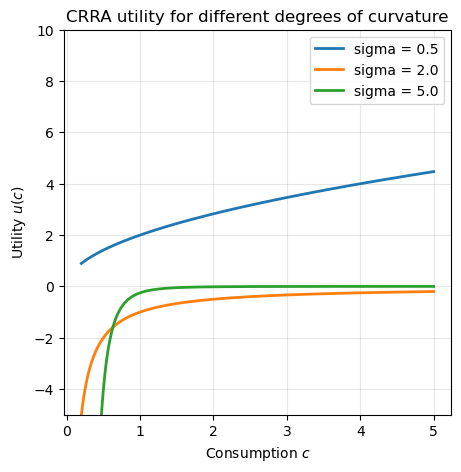

In [ ]:
# Now lets define de CRRA utility function

def utility(c, sigma):
    if sigma == 1.0: 
        return np.log(c)
    else:
        return (c**(1-sigma))/(1-sigma)
# now we can plot the utility function for different values of sigma

c_grid = np.linspace(0.2, 5.0, 300)
plt.figure(figsize=(5, 5))
for s in [0.5, 2.0, 5.0]:
    plt.plot(c_grid, utility(c_grid, s), linewidth=2, label=f"sigma = {s}")
plt.xlabel("Consumption $c$")
plt.ylabel("Utility $u(c)$")
plt.title("CRRA utility for different degrees of curvature")
plt.legend()
plt.grid(alpha=0.3)
plt.ylim(-5, 10)
plt.show()


Something to say about the different $\sigma$ levels ? 

The higher $\sigma$, the more bent the curve. A household with a high $\sigma$ loses a lot of utility when consumption falls and gains little when it rises, so it will fight hard to keep consumption flat over time. Keep this in mind: it will explain the *speed* at which the economy moves, though — as we will see — not its final destination.

### 2.2 Discounting: today is worth more than tomorrow

The household lives many periods, so we need to add up utility across time. But a peso of consumption twenty years from now is not worth the same as a peso today. We capture that with the **discount factor** $\beta$
$$
W = \sum_{t=0}^{T} \beta^{t}\, u(c_t), \qquad 0 < \beta < 1
$$

Each period is weighted by $\beta^t$, which shrinks as $t$ grows. With $\beta = 0.96$, utility 10 periods away carries weight $0.96^{10} \approx 0.66$, and 50 periods away only $0.13$.

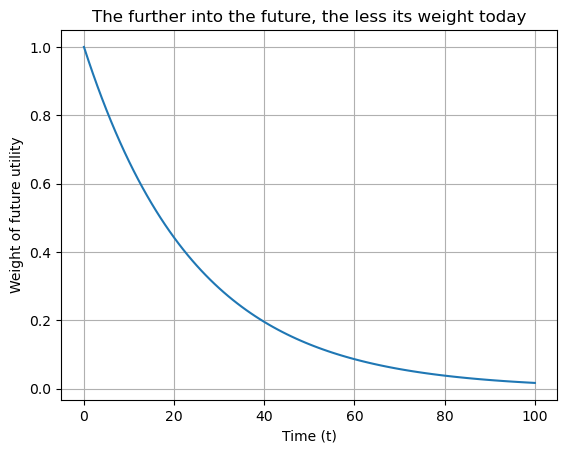

In [29]:
beta = 0.96
t = np.arange(101) #we create a time grid from 0 to 1 remember that python is 0 indexed
plt.plot(t, beta**t)
plt.xlabel("Time (t)")
plt.ylabel("Weight of future utility")
plt.title("The further into the future, the less its weight today")
plt.grid()


### 2.3 Putting the two ingredients together

Now we can turn a whole consumption path into one number. The **welfare** of a path $c_0, c_1, \dots, c_T$ is

$$
W = \sum_{t=0}^{T}\beta^{t}\,u(c_t)
$$

In Session 1 we would have written this with a `for` loop that adds one term at a time. NumPy lets us do it in one line, because operations on arrays are applied **element by element**:

- `beta**t`, with `t = np.array([0, 1, 2, 3])`, gives the array of weights $[\beta^0, \beta^1, \beta^2, \beta^3]$,
- `utility(c_path, sigma)` gives the array $[u(c_0), u(c_1), \dots]$,
- multiplying the two arrays multiplies them term by term,
- and `np.sum()` adds everything up.

In [4]:
def welfare(c_path, beta, sigma):
    """Discounted sum of utility of a consumption path c_0, c_1, ..., c_T."""
    c_path = np.array(c_path, dtype=float)   # an array of floats, even if we receive a list
    t = np.arange(len(c_path))               # 0, 1, 2, ..., T
    weights = beta**t                        # beta^0, beta^1, ..., beta^T
    return np.sum(weights * utility(c_path, sigma))

Why `dtype=float`? With $\sigma = 2$ the utility function computes $c^{-1}$. If Python receives a list of **integers**, such as `[1, 1, 1]`, NumPy refuses to raise integers to negative powers and stops with an error. Converting to floats first avoids the problem. Details like this one are part of programming: the economics is right, but the computer needs to be told exactly what kind of number it is handling.

Let's test the instrument with a simple question. Two households consume the same total, 4 units in 4 periods. One consumes 1 unit every period; the other alternates between 0.5 and 1.5.

In [5]:
sigma = 2.0
beta = 0.96

c_flat  = [1.0, 1.0, 1.0, 1.0]
c_bumpy = [0.5, 1.5, 0.5, 1.5]

W_flat  = welfare(c_flat, beta, sigma)
W_bumpy = welfare(c_bumpy, beta, sigma)

print(f"Welfare of the flat path : {W_flat:.4f}")
print(f"Welfare of the bumpy path: {W_bumpy:.4f}")

Welfare of the flat path : -3.7663
Welfare of the bumpy path: -5.0730


The flat path wins, even though both paths contain exactly the same amount of consumption. This is diminishing marginal utility at work: losing half a unit in a bad period hurts more than gaining half a unit in a good period helps. Keep this result in mind, because it is the reason why the Ramsey household **smooths** consumption.

Two remarks about the numbers:

- With $\sigma = 2$ utility is negative, $u(c) = -1/c$, so welfare is negative too. That is not a problem: only **comparisons** between paths matter, and the number closer to zero is the better one.
- Notice the formatting `{W_flat:.4f}` inside the f-string. The part after the colon tells Python to print the number as a float with 4 decimals.

## 3. A first well-being question: should the Solow economy save more?

We now have a measuring instrument, so let us go back to the question that Solow could not answer. In Session 1 we raised the saving rate from $s = 0.25$ to $s = 0.35$ and saw steady-state capital rise by 65% and output by 18%. Was that a good idea for the people living in that economy?

To answer, we need **consumption**, not capital, and we need the whole path, not only the steady state. Consumption in Solow is whatever is not saved:

$$
c_t = (1-s)\,A k_t^{\alpha}
$$

The experiment: the economy starts at the steady state of $s = 0.25$ and, at $t = 0$, either keeps $s = 0.25$ or switches to a new saving rate forever. We compare the welfare of the paths.

First we bring back the production function and the simulation of Session 1. The `for` loop is the one you already know; we only wrap it in a function, so that we can call it with different saving rates.

In [6]:
A = 1.0
alpha = 0.33
delta = 0.10
T = 250

def production(k, A, alpha):
    return A * k**alpha

def simulate_solow(s, k0, T):
    """Session 1 simulation: returns the capital path k_0, ..., k_T as an array."""
    k_path = [k0]
    for t in range(T):
        k_next = s * production(k_path[t], A, alpha) + (1 - delta) * k_path[t]
        k_path.append(k_next)
    return np.array(k_path)

# Starting point: the steady state of the economy with s = 0.25
k0 = (0.25 * A / delta)**(1 / (1 - alpha))
print(f"Initial capital (steady state with s = 0.25): {k0:.4f}")

Initial capital (steady state with s = 0.25): 3.9259


Now we simulate three economies, compute their consumption paths and plot them. We include $s = 0.33$ because $s = \alpha$ is the **golden rule**: the saving rate that maximizes steady-state consumption, as we saw in Session 1.

We store the three paths in a **dictionary**, like the ones you will meet again in Section 4.3: the key is the saving rate and the value is the consumption path.

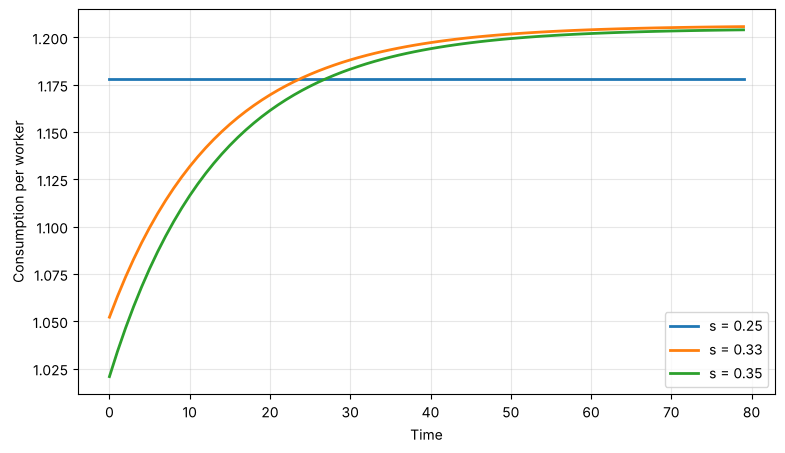

In [7]:
saving_rates = [0.25, 0.33, 0.35]
c_paths = {}                      # saving rate -> consumption path

for s in saving_rates:
    k_path = simulate_solow(s, k0, T)
    c_paths[s] = (1 - s) * production(k_path, A, alpha)

plt.figure(figsize=(9, 5))
for s in saving_rates:
    plt.plot(c_paths[s][:80], linewidth=2, label=f"s = {s}")
plt.xlabel("Time")
plt.ylabel("Consumption per worker")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Read the figure from left to right. Saving more means consuming less **today**: at $t = 0$ consumption drops from 1.18 to about 1.02 when $s$ jumps to 0.35. Only after capital has accumulated does consumption overtake its original level, and that takes 27 periods. In the long run both higher saving rates deliver more consumption than $s = 0.25$.

So the question becomes: is the long-run gain worth the short-run sacrifice? That is exactly what welfare measures.

One technical detail first. Our paths end at $T = 250$, but the economy goes on forever. Since consumption is practically constant at the end, we add the value of staying at $c_T$ forever, which is a geometric sum:

$$
\sum_{t=T+1}^{\infty}\beta^{t}\,u(c_T) = \frac{\beta^{T+1}}{1-\beta}\,u(c_T)
$$

In the code, `c_path[-1]` is the **last** element of the array: negative positions count from the end.

In [8]:
def welfare_infinite(c_path, beta, sigma):
    """Welfare of a path that stays at its last value forever after the end."""
    n_periods = len(c_path)                                  # T + 1 periods simulated
    tail = beta**n_periods * utility(c_path[-1], sigma) / (1 - beta)
    return welfare(c_path, beta, sigma) + tail

beta = 0.96
for s in saving_rates:
    print(f"s = {s}:  W = {welfare_infinite(c_paths[s], beta, sigma):.4f}")

s = 0.25:  W = -21.2265
s = 0.33:  W = -21.8040
s = 0.35:  W = -22.0600


Welfare numbers are hard to read on their own. Economists translate them into a **consumption equivalent**: by what percentage would we have to change consumption, in every period of the $s = 0.25$ path, to make the household exactly as happy as under the alternative?

With CRRA utility and $\sigma \neq 1$, multiplying every period's consumption by $(1+\lambda)$ multiplies welfare by $(1+\lambda)^{1-\sigma}$. So $\lambda$ solves

$$
(1+\lambda)^{1-\sigma}\,W_{0.25} = W_{s}
\qquad\Longrightarrow\qquad
\lambda = \left(\frac{W_{s}}{W_{0.25}}\right)^{\frac{1}{1-\sigma}} - 1
$$

In [9]:
def consumption_equivalent(W_new, W_base, sigma):
    """Percentage change in base consumption that delivers the welfare of the new path."""
    return (W_new / W_base)**(1 / (1 - sigma)) - 1

W_base = welfare_infinite(c_paths[0.25], beta, sigma)
for s in [0.33, 0.35]:
    W_s = welfare_infinite(c_paths[s], beta, sigma)
    lam = consumption_equivalent(W_s, W_base, sigma)
    print(f"Moving to s = {s} is equivalent to changing consumption by {lam:.2%} every period")

Moving to s = 0.33 is equivalent to changing consumption by -2.65% every period
Moving to s = 0.35 is equivalent to changing consumption by -3.78% every period


The format `:.2%` multiplies the number by 100, keeps two decimals and adds the percent sign.

With $\beta = 0.96$ both changes **hurt**. Even the golden rule, which maximizes steady-state consumption, is equivalent to losing about 2.6% of consumption forever: the household is impatient, and the sacrifice comes first.

Now change `beta = 0.96` to `beta = 0.99` in the cell where we computed welfare, and run the last two cells again. Both changes now **help**. The answer to "should this economy save more?" depends on how much the household values the future, and Solow has no place to put that information. Ramsey does: the household itself chooses the saving path, weighing exactly this trade-off. That is what the rest of this guide is about.

(Before moving on, set `beta` back to 0.96.)

## 4. The household's problem in continuous and discrete time

In class we use continuous time. In Python we will solve the discrete-time version, calculating capital and consumption one period after another.

**Both formulations are used in research.** We choose discrete time here to build on the Solow simulation and prepare for Bellman equations and overlapping-generations models. We can focus on bisection and shooting without introducing a numerical method for differential equations at the same time.

### 4.1 The two formulations

For this practice we assume constant population, $n=0$.

| | **Discrete time** | **Continuous time** |
|---|---|---|
| Time index | $t = 0,1,2,\dots$ | $t\in[0,\infty)$ |
| Objective | $\displaystyle\sum_{t=0}^{\infty}\beta^t u(c_t)$ | $\displaystyle\int_0^\infty e^{-\rho t}u(c(t))\,dt$ |
| Impatience | discount **factor** $0<\beta<1$ | discount **rate** $\rho>0$ |
| Constraint | $k_{t+1}=f(k_t)+(1-\delta)k_t-c_t$ | $\dot k=f(k)-\delta k-c$ |
| Optimization tool used here | **Lagrangian** | **Hamiltonian** |
| Given | $k_0$ | $k(0)$ |

The constraints express the same resource-accounting principle. Subtracting $k_t$ in the discrete version gives

$$
k_{t+1}-k_t=f(k_t)-\delta k_t-c_t.
$$

This is a change **over one economic period**. The continuous equation describes an **instantaneous rate of change**. The two formulations need not produce identical transition paths.

**A numerical step is different from an economic period.** To simulate the continuous model, a numerical algorithm approximates its trajectory using steps of size $h$. Here we instead solve a model whose decisions and constraints are formulated in discrete periods.

To connect the steady states in class and in Python, we choose

$$
\rho=\frac{1}{\beta}-1
\qquad\Longleftrightarrow\qquad
\beta=\frac{1}{1+\rho}.
$$

With the same production function and depreciation, this choice makes the two steady-state conditions coincide. It does not make the two dynamic systems identical. Section 8 checks this distinction numerically.

### 4.2 What the household chooses

The household does not choose a number. It chooses an **entire infinite sequence**, and the choices are chained together: a peso consumed at $t=0$ is a peso of capital that does not exist at $t=1$, which changes what is feasible at $t=2$, and so on forever. You cannot solve one period in isolation.

That is also why we cannot simply throw the problem at the computer. A computer cannot hold infinitely many choice variables. Everything that follows in this course — the Euler equation, the steady state, and eventually the Bellman equation — is a way of turning that infinite object into something finite.

### 4.3 Carrying the calibration: dictionaries

Our model now has five parameters instead of three, and we are about to write functions that need all of them. Passing five arguments into every function is how mistakes get made.

A **dictionary** stores values under names, in a single object.



In [31]:
par = {"A": 1.0, # productivity parameter
       "alpha": 0.33,    # capital share
        "beta":  0.96,    # discount factor
        "delta": 0.10,    # depreciation rate
        "sigma": 2.0,     # curvature of utility or risk aversion
        }

print(par)
print(f"the capital share is {par['alpha']}, the discount factor is {par['beta']}, the depreciation rate is {par['delta']}, and the curvature of utility is {par['sigma']}.")

{'A': 1.0, 'alpha': 0.33, 'beta': 0.96, 'delta': 0.1, 'sigma': 2.0}
the capital share is 0.33, the discount factor is 0.96, the depreciation rate is 0.1, and the curvature of utility is 2.0.


In [32]:
# lets define the production function 
def f(k, par):
    return par["A"] * k**par["alpha"]

def f_prime(k,par):
    return par["A"]*par["alpha"]*k**(par["alpha"]-1)

print(f(1.0, par))
print(f_prime(1.0, par))

1.0
0.33


Entonces tenemos que si $k=1$ bajo los parametros definidios $$f(k)=Ak^{\alpha}=1$$ y $$f'(k)=A \alpha k^{\alpha-1} = 0.33$$ 

## 5. The Euler equation, derived twice

In class, the professor solves the household problem with the Hamiltonian in continuous time. Here we do it in both clocks, step by step, and then we write the result in Python.

### 5.1 Discrete time: the Lagrangian

The household maximizes $\sum_{t}\beta^t u(c_t)$ subject to one constraint **per period**. Each constraint gets its own multiplier $\mu_t$:

$$
\mathcal{L} = \sum_{t=0}^{\infty}\beta^{t}\Big\{u(c_t) + \mu_t\big[f(k_t)+(1-\delta)k_t - c_t - k_{t+1}\big]\Big\}
$$

**First-order condition for $c_t$.** Consumption at $t$ appears only in period $t$:

$$
\frac{\partial \mathcal{L}}{\partial c_t} = \beta^t\big[u'(c_t) - \mu_t\big] = 0
\qquad\Longrightarrow\qquad
u'(c_t) = \mu_t
$$

**First-order condition for $k_{t+1}$.** This is the step where most mistakes happen. Tomorrow's capital appears in **two** constraints: in period $t$, where it is what we leave for tomorrow (with a minus sign), and in period $t+1$, where it produces $f(k_{t+1}) + (1-\delta)k_{t+1}$:

$$
\frac{\partial \mathcal{L}}{\partial k_{t+1}} = -\beta^{t}\mu_t + \beta^{t+1}\mu_{t+1}\big[f'(k_{t+1}) + 1 - \delta\big] = 0
$$

Replacing $\mu_t = u'(c_t)$ and $\mu_{t+1} = u'(c_{t+1})$ we obtain the **Euler equation**:

$$
\boxed{\,u'(c_t) = \beta\,u'(c_{t+1})\,\big[1 + f'(k_{t+1}) - \delta\big]\,}
$$

With CRRA utility, $u'(c) = c^{-\sigma}$, and we can solve for the growth of consumption:

$$
\frac{c_{t+1}}{c_t} = \Big[\beta\,\big(1+f'(k_{t+1})-\delta\big)\Big]^{1/\sigma}
$$

### 5.2 Continuous time: the Hamiltonian

In continuous time we write the present-value Hamiltonian, with a shadow price $\lambda$ for capital:

$$
H = u(c)\,e^{-\rho t} + \lambda\,\big[f(k) - \delta k - c\big]
$$

The trick is that **both** first-order conditions can be written in terms of the same object, $-\dot\lambda/\lambda$. Then we only have to set them equal.

**First condition, $\partial H/\partial c = 0$:**

$$
u'(c)\,e^{-\rho t} = \lambda
$$

Take logarithms, $\ln u'(c) - \rho t = \ln\lambda$, and differentiate with respect to time. With CRRA, $\frac{u''(c)\,c}{u'(c)} = -\sigma$, so

$$
-\sigma\,\frac{\dot c}{c} - \rho = \frac{\dot\lambda}{\lambda}
\qquad\Longrightarrow\qquad
\sigma\,\frac{\dot c}{c} + \rho = -\frac{\dot\lambda}{\lambda}
$$

**Second condition, $\partial H/\partial k = -\dot\lambda$:**

$$
\lambda\,\big[f'(k) - \delta\big] = -\dot\lambda
\qquad\Longrightarrow\qquad
f'(k) - \delta = -\frac{\dot\lambda}{\lambda}
$$

**Set the two expressions for $-\dot\lambda/\lambda$ equal.** The shadow price disappears and we obtain

$$
\boxed{\,\frac{\dot c}{c} = \frac{1}{\sigma}\big[f'(k) - \delta - \rho\big]\,}
$$

The system is closed by the transversality condition, $\lim_{t\to\infty}\lambda(t)\,k(t) = 0$, which will do real work in Section 10.

### 5.3 How to read the Euler equation

$$
\underbrace{u'(c_t)}_{\text{cost of saving one unit today}}
=
\underbrace{\beta}_{\text{impatience}}
\times
\underbrace{\big[1+f'(k_{t+1})-\delta\big]}_{\text{units received tomorrow}}
\times
\underbrace{u'(c_{t+1})}_{\text{value of each unit tomorrow}}
$$

- At the optimum the household is **indifferent** between consuming the last unit today and saving it. If it were not, it would move consumption from one period to the other.
- If capital pays more than the household's impatience, $f'(k) - \delta > \rho$, it pays to postpone consumption: **consumption grows**. If it pays less, consumption falls.
- $1/\sigma$ is the **elasticity of intertemporal substitution**. With a large $\sigma$ the household wants a smooth path and reacts little to the interest rate. As we said in Section 2.1, $\sigma$ governs the **speed** of the economy.

### 5.4 The Euler equation in Python

The discrete Euler equation is a rule: given tomorrow's capital, it gives the growth factor of consumption. Let's write it as a function that reads the parameters from our dictionary `par`.

In [12]:
def consumption_growth(k_next, par):
    """Gross growth of consumption, c_{t+1}/c_t, from the discrete Euler equation."""
    gross_return = 1 + f_prime(k_next, par) - par["delta"]
    return (par["beta"] * gross_return)**(1 / par["sigma"])

for k in [1.0, 3.0, 5.0, 8.0]:
    growth = consumption_growth(k, par)
    print(f"k = {k:>4}:  c_(t+1)/c_t = {growth:.4f}")

k =  1.0:  c_(t+1)/c_t = 1.0866
k =  3.0:  c_(t+1)/c_t = 1.0078
k =  5.0:  c_(t+1)/c_t = 0.9858
k =  8.0:  c_(t+1)/c_t = 0.9709


When capital is scarce ($k = 1$) its marginal product is high and consumption grows; when capital is abundant ($k = 8$) consumption falls. Somewhere between 3 and 5 the growth factor is exactly 1: that is the steady state, which we find in the next section.

The `:>4` inside the f-string only aligns the numbers to the right in a space of 4 characters, so that the output is easier to read.

## 6. The steady state: the modified golden rule

In the steady state consumption does not change, $c_{t+1} = c_t$. The discrete Euler equation then says

$$
1 = \beta\big[1 + f'(k^*) - \delta\big]
\qquad\Longrightarrow\qquad
f'(k^*) = \frac{1}{\beta} - 1 + \delta \equiv R
$$

In continuous time, with $\dot c = 0$, we get $f'(k^*) = \rho + \delta$. Since $\rho = 1/\beta - 1$, **it is the same condition**.

With Cobb-Douglas, $\alpha A k^{\alpha-1} = R$, so

$$
k^* = \left(\frac{\alpha A}{R}\right)^{\frac{1}{1-\alpha}},
\qquad
c^* = f(k^*) - \delta k^*
$$

The second expression comes from the resource constraint with $k_{t+1} = k_t$: whatever is produced and not used to replace depreciated capital is consumed.

Compare with the **golden rule** of Session 1, the capital stock that maximizes steady-state consumption: $f'(k_{gold}) = \delta$ (there is no population growth here). The Ramsey condition has an extra term, $1/\beta - 1 > 0$. That is why it is called the **modified** golden rule.

In [13]:
# Steady state of the Ramsey model (modified golden rule)
R = 1 / par["beta"] - 1 + par["delta"]
k_ss = (par["alpha"] * par["A"] / R)**(1 / (1 - par["alpha"]))
c_ss = f(k_ss, par) - par["delta"] * k_ss

# Golden rule: maximizes steady-state consumption
k_gold = (par["alpha"] * par["A"] / par["delta"])**(1 / (1 - par["alpha"]))
c_gold = f(k_gold, par) - par["delta"] * k_gold

print(f"Ramsey steady state : k* = {k_ss:.4f},  c* = {c_ss:.4f}")
print(f"Golden rule         : k  = {k_gold:.4f},  c  = {c_gold:.4f}")
print(f"Euler equation at k*: c_(t+1)/c_t = {consumption_growth(k_ss, par):.10f}")

Ramsey steady state : k* = 3.5329,  c* = 1.1634
Golden rule         : k  = 5.9416,  c  = 1.2063
Euler equation at k*: c_(t+1)/c_t = 1.0000000000


The last line is a **validation**, in the spirit of Session 1: at the steady state the Euler equation must give a growth factor of exactly 1, and it does.

Let's see the two capital stocks on a graph. The curve is the consumption that each capital stock can sustain forever, $c = f(k) - \delta k$. A new instruction: `plt.axvline(value)` draws a **vertical** line, the sibling of the `plt.axhline` we used in Session 1.

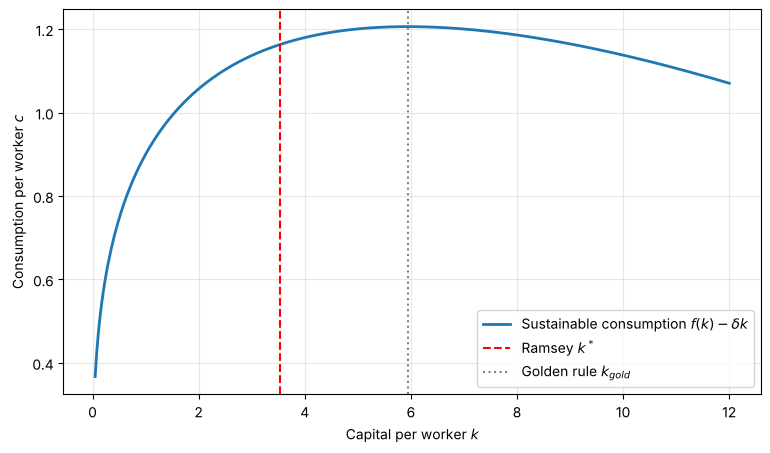

In [14]:
k_grid = np.linspace(0.05, 12, 400)
c_sustainable = f(k_grid, par) - par["delta"] * k_grid

plt.figure(figsize=(9, 5))
plt.plot(k_grid, c_sustainable, linewidth=2, label=r"Sustainable consumption $f(k)-\delta k$")
plt.axvline(k_ss, color="red", linestyle="--", label=r"Ramsey $k^*$")
plt.axvline(k_gold, color="gray", linestyle=":", label=r"Golden rule $k_{gold}$")
plt.xlabel("Capital per worker $k$")
plt.ylabel("Consumption per worker $c$")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The Ramsey household stops **before** the top of the curve. Reaching $k_{gold}$ would require sacrificing consumption today to gain consumption in a distant future, and an impatient household does not find that worthwhile. It is the lesson of Section 3, now coming from the household's own choice: **Ramsey never accumulates too much capital**, so it is never dynamically inefficient.

## 7. The phase diagram: a continuous-time reference

Before simulating, we draw the **continuous-time phase diagram seen in class**, with $n=0$:

$$
\dot k=f(k)-\delta k-c,
\qquad
\frac{\dot c}{c}=\frac{1}{\sigma}\big[f'(k)-\delta-\rho\big].
$$

The horizontal axis is capital $k$ and the vertical axis is consumption $c$. The two loci are:

- **$\dot k=0$:** $c=f(k)-\delta k$. Below this curve, capital increases; above it, capital decreases.
- **$\dot c=0$:** the vertical line $k=k^*$, because $f'(k^*)=\rho+\delta$. To its left, consumption increases; to its right, consumption decreases.

We calibrated $\rho=1/\beta-1$, so $\rho+\delta=R$. This lets us use **f_prime(K, par) - R** to obtain the sign of the **continuous-time** consumption movement.

To draw the arrows we use three NumPy and Matplotlib tools:

- **np.meshgrid(k_values, c_values)** builds a **grid of points**: every combination of a capital value and a consumption value. With 15 of each, we get $15\times15=225$ points stored in two matrices, **K** and **C**.
- **np.sign(x)** returns $1$ for a positive value, $-1$ for a negative value, and $0$ for zero. We use signs to show directions rather than speeds.
- **plt.quiver(K, C, u, v)** draws an arrow in direction $(u,v)$ at each point.

The following figure is a qualitative reference for the continuous model. The trajectories in Section 10 will be calculated with the **discrete-time equations**.

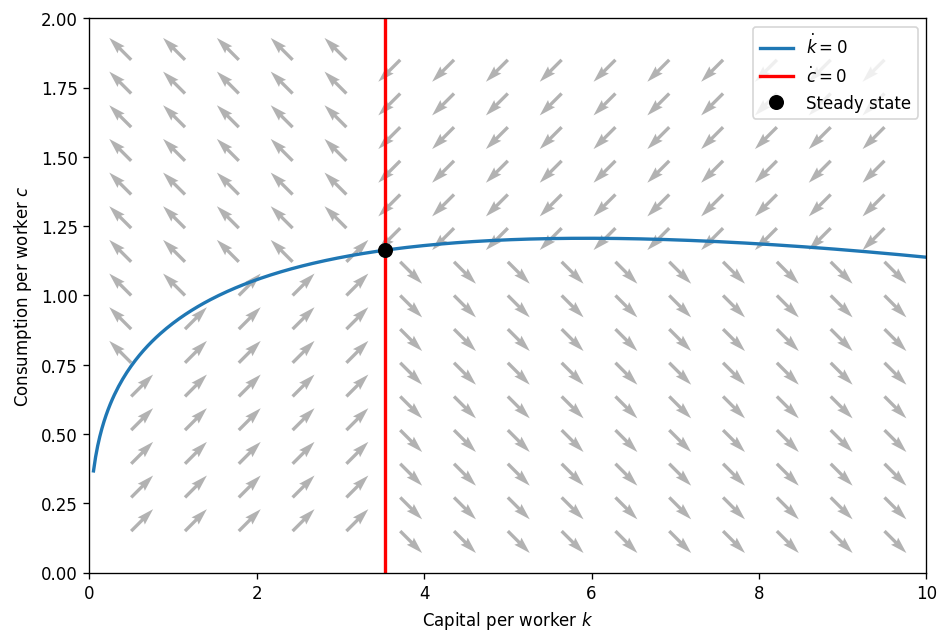

In [15]:
# 1. The two continuous-time loci (reference diagram)
k_grid = np.linspace(0.05, 10, 400)
c_locus = f(k_grid, par) - par["delta"] * k_grid        # dot k = 0

# 2. A coarse grid of points where we draw arrows
k_values = np.linspace(0.5, 9.5, 15)
c_values = np.linspace(0.15, 1.85, 15)
K, C = np.meshgrid(k_values, c_values)

# 3. Signs of continuous-time motion at each point
dK = f(K, par) - par["delta"] * K - C      # continuous-time capital drift
dC = f_prime(K, par) - R                   # same sign as dot c / c, since rho + delta = R

plt.figure(figsize=(9, 6))
plt.quiver(K, C, np.sign(dK), np.sign(dC), color="gray", alpha=0.6)
plt.plot(k_grid, c_locus, linewidth=2, label=r"$\dot k = 0$")
plt.axvline(k_ss, color="red", linewidth=2, label=r"$\dot c = 0$")
plt.plot(k_ss, c_ss, "ko", markersize=8, label="Steady state")
plt.xlim(0, 10)
plt.ylim(0, 2)
plt.xlabel("Capital per worker $k$")
plt.ylabel("Consumption per worker $c$")
plt.legend(loc="upper right")
plt.show()

Read the four regions as in the continuous-time diagram from class. Below the capital locus and to the left of $k^*$, both variables increase; above the locus and to the right, both decrease. In the other two regions they move in opposite directions.

**These are continuous-time directions.** In the discrete model, the Euler equation uses **next period's capital**:

$$
\frac{c_{t+1}}{c_t}
=\left[\beta\big(1+f'(k_{t+1})-\delta\big)\right]^{1/\sigma}.
$$

Thus, for positive consumption, $\Delta c_t=0$ requires $k_{t+1}=k^*$, not necessarily $k_t=k^*$. Replacing tomorrow's capital with today's can change the sign of consumption growth away from the steady state. The vertical line and arrows above should therefore not be interpreted as the exact discrete-time field.

The diagram introduces the economic idea of a **saddle path**: given $k_0$, we must choose the initial consumption compatible with the optimal transition. In Section 10, shooting will find that choice using the actual discrete equations.

## 8. Comparing the two formulations

We now check two distinct points: our parameter choice makes the steady states coincide, while the Euler growth expressions can differ away from that steady state.

### 8.1 The same steady state under our calibration

In continuous time the steady state satisfies $f'(k^*)=\rho+\delta$. In discrete time it satisfies $f'(k^*)=1/\beta-1+\delta$. Setting $\rho=1/\beta-1$ makes these conditions identical, so the formulas give the same $k^*$.

In [16]:
rho = 1 / par["beta"] - 1
k_ss_continuous = (par["alpha"] * par["A"] / (rho + par["delta"]))**(1 / (1 - par["alpha"]))

print(f"rho           : {rho:.6f}")
print(f"k* discrete   : {k_ss:.10f}")
print(f"k* continuous : {k_ss_continuous:.10f}")

rho           : 0.041667
k* discrete   : 3.5328789172
k* continuous : 3.5328789172


### 8.2 Comparing consumption-growth expressions

At a given capital value $k$, compare:

$$
\text{discrete:}\quad
\frac{1}{\sigma}\ln\!\left[\beta\big(1+f'(k)-\delta\big)\right],
\qquad
\text{continuous:}\quad
\frac{1}{\sigma}\big[f'(k)-\delta-\rho\big].
$$

In an actual discrete trajectory the capital argument is $k_{t+1}$; in the continuous system it is current capital. This graph evaluates both expressions at the same numerical value of $k$ to compare their shapes. It does not compare two complete simulated trajectories.

The expressions are not identical. With $\beta=1/(1+\rho)$, the discrete expression can be written as

$$
\frac{1}{\sigma}
\left[\ln\big(1+f'(k)-\delta\big)-\ln(1+\rho)\right].
$$

When the net return and discount rate are small, using $\ln(1+x)\approx x$ gives an approximation to the continuous expression. The next graph shows the difference for our calibration. Our functions work on arrays, so we evaluate a whole grid of capital values at once.

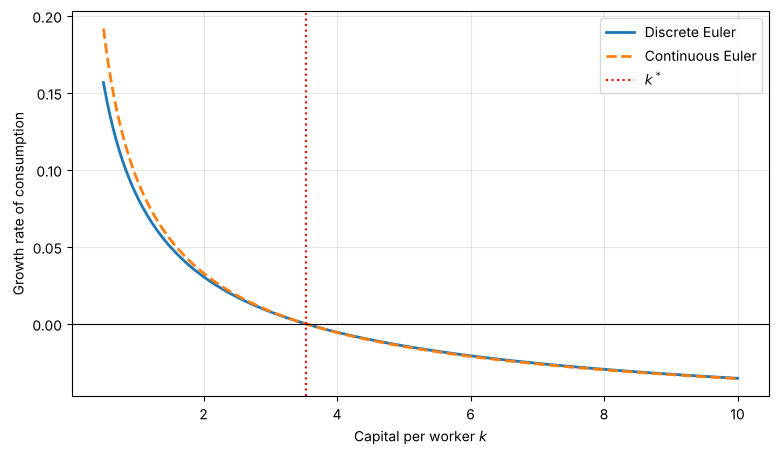

Largest difference on the grid: 0.0350


In [17]:
k_grid = np.linspace(0.5, 10, 200)

growth_discrete = np.log(consumption_growth(k_grid, par))
growth_continuous = (f_prime(k_grid, par) - par["delta"] - rho) / par["sigma"]

plt.figure(figsize=(9, 5))
plt.plot(k_grid, growth_discrete, linewidth=2, label="Discrete Euler")
plt.plot(k_grid, growth_continuous, linewidth=2, linestyle="--", label="Continuous Euler")
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(k_ss, color="red", linestyle=":", label=r"$k^*$")
plt.xlabel("Capital per worker $k$")
plt.ylabel("Growth rate of consumption")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

gap = np.max(np.abs(growth_discrete - growth_continuous))
print(f"Largest difference on the grid: {gap:.4f}")

Both curves cross zero at $k^*$ because of our choice $\rho=1/\beta-1$. They differ away from it, especially at low capital values where returns are high and the approximation $\ln(1+x)\approx x$ is less accurate.

The shared steady state helps us connect the calculation in Python with the result from class. It does not establish that the continuous and discrete transition paths coincide.

**np.abs()** takes absolute values element by element, and **np.max()** returns the largest element of an array.

## 9. Solving it without a formula

Cobb-Douglas let us solve $f'(k^*) = R$ by hand. With almost any other production function we could not. So let us learn to solve it numerically — and, following the principle from Session 1, validate the algorithm against the answer we already know.

We need the $k$ where

$$
g(k) \equiv f'(k) - R = 0
$$

This is called **root finding**, and the simplest method is **bisection**:

1. Start with an interval $[k_{lo}, k_{hi}]$ where $g$ **changes sign** — so a root must be inside.
2. Evaluate $g$ at the midpoint.
3. Keep whichever half still contains the sign change. The interval is now half as long.
4. Repeat until the interval is shorter than the tolerance.

Notice the shape: it is the same `while` loop from Session 1, repeating an operation until an error measure falls below a tolerance. Only the operation changed.

In [ ]:
def euler_gap(k, par):
    """g(k) = f'(k) - R. Its root is the steady state."""
    R = 1/par["beta"] - 1 + par["delta"]
    return f_prime(k, par) - R


lo, hi = 0.1, 50.0
tol = 1e-10
iteration = 0
max_iter = 200

while (hi - lo) > tol and iteration < max_iter:
    mid = 0.5 * (lo + hi)
    if euler_gap(lo, par) * euler_gap(mid, par) < 0:   # sign change on the left half
        hi = mid
    else:                                              # sign change on the right half
        lo = mid
    iteration = iteration + 1

k_bisection = 0.5 * (lo + hi)

print(f"k* by bisection : {k_bisection:.10f}")
print(f"k* by formula   : {k_ss:.10f}")
print(f"Difference      : {abs(k_bisection - k_ss):.2e}")
print(f"Iterations      : {iteration}")

### 9.1 Back to Session 1: the threshold of the poverty trap

Bisection is useful far beyond this model. In Session 1 we studied an economy that pays a fixed amount $p$ abroad. It has two steady states, $k_L$ and $k_H$, and the `while` loop of the fixed point can never find $k_L$, because that steady state repels. We located it only approximately, on a grid.

Bisection finds it to ten decimals. We only need an interval where $h(k) - p = sAk^\alpha - p - \delta k$ changes sign. We use the calibration of Session 1, with $s = 0.25$ and $p = 0.12$.

In [19]:
def trap_gap(k):
    """Session 1 problem: investment minus the payment minus depreciation."""
    s, p = 0.25, 0.12
    return s * par["A"] * k**par["alpha"] - p - par["delta"] * k

lo, hi = 0.02, 0.75          # trap_gap(lo) < 0 and trap_gap(hi) > 0
iteration = 0

while (hi - lo) > tol and iteration < max_iter:
    mid = 0.5 * (lo + hi)
    if trap_gap(lo) * trap_gap(mid) < 0:
        hi = mid
    else:
        lo = mid
    iteration = iteration + 1

print(f"k_L by bisection: {0.5 * (lo + hi):.10f}  ({iteration} iterations)")

k_L by bisection: 0.1569881144  (33 iterations)


## 10. Simulating the Ramsey economy: the shooting method

### 10.1 The problem

In Solow, simulating was easy: given $k_0$, the law of motion gave $k_1$, then $k_2$, and so on. In Ramsey we have two equations,

$$
k_{t+1} = f(k_t) + (1-\delta)k_t - c_t,
\qquad
c_{t+1} = c_t\,\Big[\beta\big(1+f'(k_{t+1})-\delta\big)\Big]^{1/\sigma}
$$

but only **one** initial condition: $k_0$ is given by history, while $c_0$ is chosen by the household. Every value of $c_0$ produces a path that satisfies both equations. Which one is the optimal one?

The answer is the **transversality condition**: the household neither runs out of capital nor accumulates capital that it never consumes. In the phase diagram this means that the economy must ride the **saddle path** to the steady state. Any other $c_0$ either exhausts the capital stock or accumulates capital forever.

### 10.2 One simulation

We write a function that, given $c_0$ and $k_0$, simulates the system for $T$ periods. Three new Python ideas:

1. **Preallocation.** Instead of starting with a list and using `.append()`, as in Session 1, we create arrays full of zeros with `np.zeros(T + 1)` and fill them period by period. It is faster, and the arrays have a size that we know in advance.
2. **`break`.** It stops a loop immediately. We use it when the path has clearly gone wrong: if capital becomes negative, the household consumed too much; if capital grows beyond twice the golden rule, it consumed too little. The function reports which case happened in a **status** string.
3. **Slicing.** `k[a:b]` takes the elements from position `a` up to position `b - 1`. At the end we return only the periods that were actually simulated, `k[: t + 2]`.

In [20]:
def simulate_ramsey(c0, k0, par, T):
    """Simulate the Ramsey system from (k0, c0). Returns k, c and a status."""
    k = np.zeros(T + 1)
    c = np.zeros(T + 1)
    k[0] = k0
    c[0] = c0
    status = "still running"

    for t in range(T):
        k[t + 1] = f(k[t], par) + (1 - par["delta"]) * k[t] - c[t]
        if k[t + 1] <= 0:                  # capital exhausted: c0 was too high
            status = "too high"
            break
        c[t + 1] = c[t] * consumption_growth(k[t + 1], par)
        if k[t + 1] > 2 * k_gold:          # capital explodes: c0 was too low
            status = "too low"
            break

    return k[: t + 2], c[: t + 2], status

Let's try three guesses of $c_0$ from $k_0 = 1$, below the steady state. Notice how we use a function that returns several values: `k, c, status = simulate_ramsey(...)` **unpacks** the three results into three variables.

c0 = 0.60: too low after 23 periods
c0 = 0.70: too low after 45 periods
c0 = 0.80: too high after 8 periods


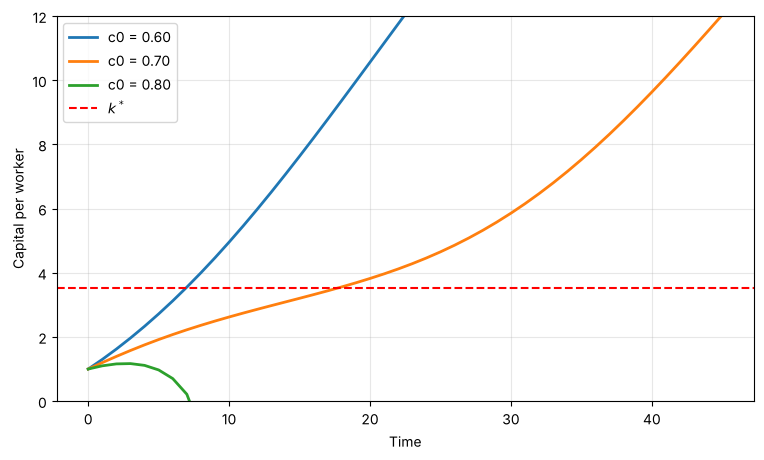

In [21]:
k0 = 1.0
T = 200

plt.figure(figsize=(9, 5))
for c0 in [0.60, 0.70, 0.80]:
    k, c, status = simulate_ramsey(c0, k0, par, T)
    print(f"c0 = {c0:.2f}: {status} after {len(k) - 1} periods")
    plt.plot(k, linewidth=2, label=f"c0 = {c0:.2f}")
plt.axhline(k_ss, color="red", linestyle="--", label=r"$k^*$")
plt.ylim(0, 12)
plt.xlabel("Time")
plt.ylabel("Capital per worker")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

With $c_0 = 0.80$ the household eats its capital in a few periods. With $c_0 = 0.60$ it accumulates without limit. And $c_0 = 0.70$ looks good for a while, approaches $k^*$, and then explodes too: it is close to the right value, but not on it.

### 10.3 Shooting: bisection on $c_0$

The figure tells us what to do. A $c_0$ that is too high makes capital collapse, a $c_0$ that is too low makes it explode, and the right $c_0$ lies in between. That is a sign change, so we can use **the same bisection** of Section 9. Instead of looking for the $k$ where a function changes sign, we look for the $c_0$ where the status changes from "too low" to "too high". This is why the method is called **shooting**: we aim $c_0$, see where the path lands, and correct the aim.

Notice `tol=1e-10` in the definition of the function: it is a **default argument**. If we do not pass a tolerance when we call the function, it uses that value.

In [22]:
def shoot(k0, par, T, c_lo, c_hi, tol=1e-10, max_iter=200):
    """Find the c0 that puts the economy on the saddle path, by bisection."""
    iteration = 0
    while (c_hi - c_lo) > tol and iteration < max_iter:
        c_mid = 0.5 * (c_lo + c_hi)
        k, c, status = simulate_ramsey(c_mid, k0, par, T)
        if status == "too high":
            c_hi = c_mid
        else:                      # "too low" or "still running"
            c_lo = c_mid
        iteration = iteration + 1
    return 0.5 * (c_lo + c_hi)

c0_star = shoot(k0, par, T, c_lo=0.0, c_hi=f(k0, par))
print(f"Saddle-path consumption from k0 = {k0}: c0 = {c0_star:.6f}")

Saddle-path consumption from k0 = 1.0: c0 = 0.703732


The bracket is easy to choose: $c_0 = 0$ is certainly too low, and consuming all of today's output, $c_0 = f(k_0)$, is certainly too high.

### 10.4 The saddle path

Let's compare the saddle path with two paths that start only 1% away from it. The underscore `_` is a common name for a result that we do not need.

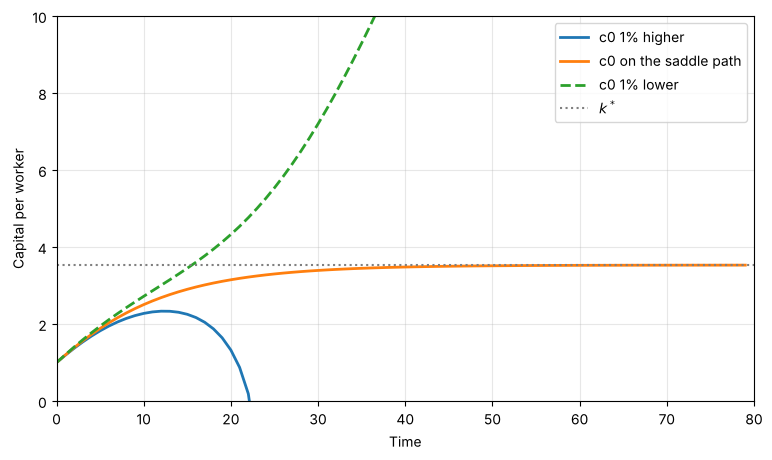

In [23]:
k_sad, c_sad, status = simulate_ramsey(c0_star, k0, par, T)
k_up, c_up, _ = simulate_ramsey(1.01 * c0_star, k0, par, T)
k_dn, c_dn, _ = simulate_ramsey(0.99 * c0_star, k0, par, T)

plt.figure(figsize=(9, 5))
plt.plot(k_up, linewidth=2, label="c0 1% higher")
plt.plot(k_sad[:80], linewidth=2, label="c0 on the saddle path")
plt.plot(k_dn, linewidth=2, linestyle="--", label="c0 1% lower")
plt.axhline(k_ss, color="gray", linestyle=":", label=r"$k^*$")
plt.xlim(0, 80)
plt.ylim(0, 10)
plt.xlabel("Time")
plt.ylabel("Capital per worker")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

A 1% mistake in $c_0$ is enough to exhaust the capital stock in about 20 periods, or to send capital beyond the golden rule. Only the saddle path satisfies the transversality condition.

We plotted only the first 80 periods of the saddle path. If you plot all of them you will see it leave the steady state at the end. That is not an economic result: the saddle path is unstable, so the tiny rounding error left by the bisection (about $10^{-10}$) grows every period until it becomes visible. This is why we only trust the first periods of a shooting solution.

Finally, let's put saddle paths on the phase diagram, from a $k_0$ below the steady state and from one above it.

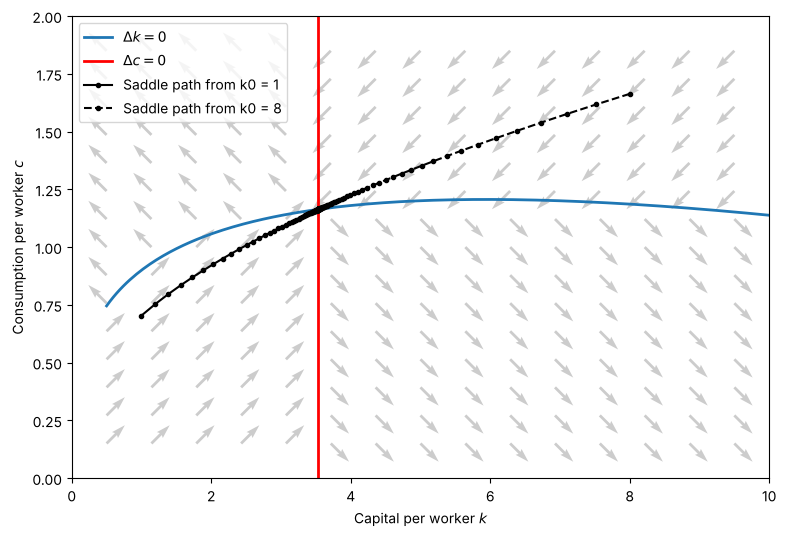

In [24]:
k0_above = 8.0
c0_above = shoot(k0_above, par, T, c_lo=0.0, c_hi=f(k0_above, par) + (1 - par["delta"]) * k0_above)
k_above, c_above, _ = simulate_ramsey(c0_above, k0_above, par, T)

plt.figure(figsize=(9, 6))
plt.quiver(K, C, np.sign(dK), np.sign(dC), color="gray", alpha=0.4)
plt.plot(k_grid, f(k_grid, par) - par["delta"] * k_grid, linewidth=2, label=r"$\Delta k = 0$")
plt.axvline(k_ss, color="red", linewidth=2, label=r"$\Delta c = 0$")
plt.plot(k_sad[:80], c_sad[:80], "k.-", label="Saddle path from k0 = 1")
plt.plot(k_above[:80], c_above[:80], "k.--", label="Saddle path from k0 = 8")
plt.xlim(0, 10)
plt.ylim(0, 2)
plt.xlabel("Capital per worker $k$")
plt.ylabel("Consumption per worker $c$")
plt.legend(loc="upper left")
plt.show()

Each dot is one period. Notice that the dots are far apart at the beginning and pile up near the steady state: the economy moves fast when it is far from $k^*$ and slowly when it is close, exactly as in Solow.

### 10.5 Back to the question of Section 3

In Section 3 the Solow economy sat at the steady state of $s = 0.25$, $k_0 = 3.93$, and we asked whether it should save more. Now we can ask the Ramsey household what it would do from that same starting point. Since $k_0 = 3.93$ is **above** the Ramsey $k^* = 3.53$, the household finds the Solow economy to be over-saving: it consumes more at the beginning and lets capital fall.

In [25]:
k0_solow = (0.25 * par["A"] / par["delta"])**(1 / (1 - par["alpha"]))
c_hi = f(k0_solow, par) + (1 - par["delta"]) * k0_solow
c0_opt = shoot(k0_solow, par, T, c_lo=0.0, c_hi=c_hi)
k_opt, c_opt, _ = simulate_ramsey(c0_opt, k0_solow, par, T)

c_opt_trusted = c_opt[:100]                    # the periods we trust
W_opt = welfare_infinite(c_opt_trusted, par["beta"], par["sigma"])
W_solow = welfare_infinite(c_paths[0.25], par["beta"], par["sigma"])

print(f"Consumption at t = 0: Solow {c_paths[0.25][0]:.4f},  Ramsey {c0_opt:.4f}")
print(f"Gain of the optimal path: {consumption_equivalent(W_opt, W_solow, par['sigma']):.2%} of consumption every period")

Consumption at t = 0: Solow 1.1778,  Ramsey 1.2166
Gain of the optimal path: 0.12% of consumption every period


The optimal path is better than keeping $s = 0.25$, and by construction it is better than **any** constant saving rate: the household chooses the best possible path, period by period. This is the sense in which Ramsey answers the question that Solow could not.

## 11. The problem of the day: public spending, unexpected or announced

This is the problem we solved on the board. The government spends $g$ per worker, financed with lump-sum taxes. The resource constraint becomes

$$
k_{t+1} = f(k_t) + (1-\delta)k_t - c_t - g_t
$$

while the Euler equation does not change, because $g_t$ does not depend on the household's choices. Therefore $k^*$ does not change, and steady-state consumption falls one for one with spending: $c^*_{new} = c^* - g$.

We study a permanent spending of $g = 0.15$ in two scenarios:

- **(e) Unexpected and permanent:** spending starts at $t = 0$ and nobody knew it was coming.
- **(d) Announced:** at $t = 0$ the government announces that spending will start at $t_1 = 10$.

### 11.1 A policy is an array

A policy that changes over time is just an array with one value per period. To build it we use **slicing for assignment**: `g_path[t1:] = G` writes the value `G` in every position from `t1` to the end.

In [26]:
G = 0.15
t1 = 10
T = 200

g_unexpected = np.zeros(T)
g_unexpected[0:] = G           # spending from t = 0 onward

g_announced = np.zeros(T)
g_announced[t1:] = G           # zero before t1, G from t1 onward

print("Announced policy, first 15 periods:", g_announced[:15])

Announced policy, first 15 periods: [0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.15 0.15 0.15 0.15
 0.15]


Now we copy our two functions and add the spending. Only the lines marked `# NEW` change. The new argument `g_path` enters the resource constraint, and `shoot_policy` simply passes it on to the simulation.

In [27]:
def simulate_policy(c0, k0, par, T, g_path):
    """Ramsey system with government spending g_t in the resource constraint."""
    k = np.zeros(T + 1)
    c = np.zeros(T + 1)
    k[0] = k0
    c[0] = c0
    status = "still running"

    for t in range(T):
        k[t + 1] = f(k[t], par) + (1 - par["delta"]) * k[t] - c[t] - g_path[t]   # NEW
        if k[t + 1] <= 0:
            status = "too high"
            break
        c[t + 1] = c[t] * consumption_growth(k[t + 1], par)
        if k[t + 1] > 2 * k_gold:
            status = "too low"
            break

    return k[: t + 2], c[: t + 2], status


def shoot_policy(k0, par, T, g_path, c_lo, c_hi, tol=1e-10, max_iter=200):   # NEW
    """Shooting with a spending path."""
    iteration = 0
    while (c_hi - c_lo) > tol and iteration < max_iter:
        c_mid = 0.5 * (c_lo + c_hi)
        k, c, status = simulate_policy(c_mid, k0, par, T, g_path)            # NEW
        if status == "too high":
            c_hi = c_mid
        else:
            c_lo = c_mid
        iteration = iteration + 1
    return 0.5 * (c_lo + c_hi)

### 11.2 Scenario (e): unexpected and permanent

On the board we argued that consumption jumps immediately to $c^* - g$ and capital never moves. Let's see whether the computer agrees.

In [28]:
c0_unexp = shoot_policy(k_ss, par, T, g_unexpected, c_lo=0.0, c_hi=c_ss)
k_unexp, c_unexp, _ = simulate_policy(c0_unexp, k_ss, par, T, g_unexpected)

print(f"c* before the policy   : {c_ss:.6f}")
print(f"c0 chosen (unexpected) : {c0_unexp:.6f}")
print(f"c* - G                 : {c_ss - G:.6f}")
print(f"Largest change in k over 50 periods: {np.max(np.abs(k_unexp[:50] - k_ss)):.2e}")

c* before the policy   : 1.163352
c0 chosen (unexpected) : 1.013352
c* - G                 : 1.013352
Largest change in k over 50 periods: 9.79e-08


The household absorbs the whole policy in consumption, at once: the jump is exactly $g$ and capital stays at $k^*$. A lump-sum tax does not distort the saving decision, it only takes resources away.

### 11.3 Scenario (d): announced

Now the policy is announced at $t = 0$ but starts at $t_1 = 10$. We shoot again, with the announced spending path. The bracket is natural: consuming $c^*$ as if nothing happened is too high, and cutting consumption by the full $g$ today is too low.

In [29]:
c0_ann = shoot_policy(k_ss, par, T, g_announced, c_lo=c_ss - G, c_hi=c_ss)
k_ann, c_ann, _ = simulate_policy(c0_ann, k_ss, par, T, g_announced)

drop = c_ss - c0_ann
print(f"Fall in consumption at the announcement: {drop:.4f}  ({drop / G:.0%} of the spending)")
print(f"Capital at t1 = {t1}: {k_ann[t1]:.4f}   (k* = {k_ss:.4f})")

Fall in consumption at the announcement: 0.0396  (26% of the spending)
Capital at t1 = 10: 4.1147   (k* = 3.5329)


To compare the two scenarios we draw two panels side by side. A new Matplotlib tool: `fig, axes = plt.subplots(1, 2)` creates one figure with two panels. `axes[0]` is the left panel and `axes[1]` the right one, and instead of `plt.plot` we write `axes[0].plot`. The same happens with the labels: `axes[0].set_xlabel(...)`.

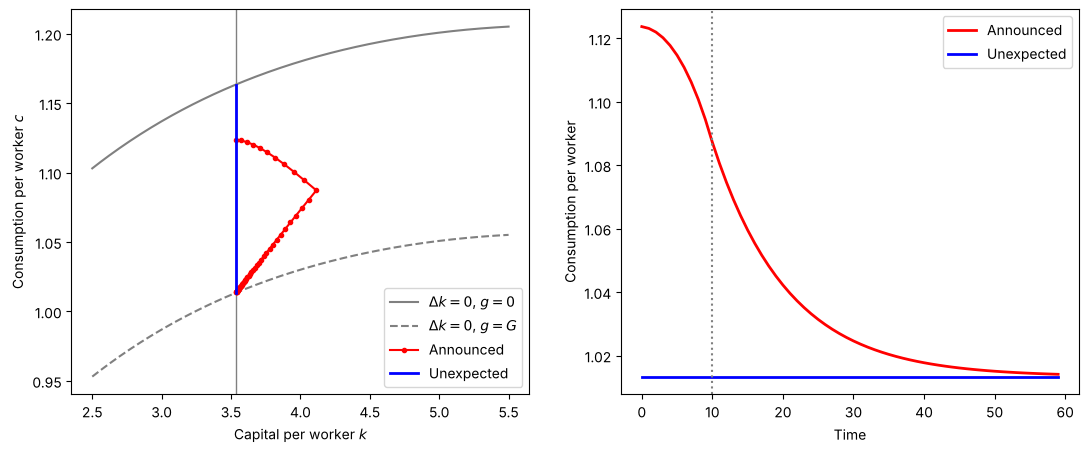

In [30]:
n_show = 60
k_grid = np.linspace(2.5, 5.5, 200)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left panel: the phase diagram
axes[0].plot(k_grid, f(k_grid, par) - par["delta"] * k_grid, color="gray", label=r"$\Delta k = 0$, $g = 0$")
axes[0].plot(k_grid, f(k_grid, par) - par["delta"] * k_grid - G, color="gray", linestyle="--", label=r"$\Delta k = 0$, $g = G$")
axes[0].axvline(k_ss, color="gray", linewidth=1)
axes[0].plot(k_ann[:n_show], c_ann[:n_show], "r.-", label="Announced")
axes[0].plot([k_ss, k_ss], [c_ss, c_ss - G], "b-", linewidth=2, label="Unexpected")
axes[0].set_xlabel("Capital per worker $k$")
axes[0].set_ylabel("Consumption per worker $c$")
axes[0].legend()

# Right panel: consumption over time
time = np.arange(n_show)
axes[1].plot(time, c_ann[:n_show], "r", linewidth=2, label="Announced")
axes[1].plot(time, c_unexp[:n_show], "b", linewidth=2, label="Unexpected")
axes[1].axvline(t1, color="gray", linestyle=":")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Consumption per worker")
axes[1].legend()

plt.show()

Read the left panel as we did on the board, keeping in mind that the plotted trajectory is discrete:

1. At $t=0$, the announcement lowers consumption by about a quarter of $g$, less than the full spending increase.
2. Before $t_1$, spending is still zero. Consumption is below the old constant-capital curve, so capital grows above $k^*$. The discrete Euler equation then uses $k_{t+1}$ to calculate the change in consumption.
3. From $t_1$ onward, the accumulated capital is used during the adjustment toward the new steady state $(k^*,c^*-g)$.

**Continuous and discrete time need different wording here.** In the continuous model, consumption is continuous at the anticipated implementation date $t_1$; the initial jump occurs when the news arrives at $t=0$.

In our discrete simulation, consumption can change between $t_1-1$ and $t_1$, just as it changes between other periods. Its change satisfies

$$
c_{t_1}
=c_{t_1-1}
\left[\beta\big(1+f'(k_{t_1})-\delta\big)\right]^{1/\sigma}.
$$

Knowing the implementation date does not require $c_{t_1}=c_{t_1-1}$. The announcement is already incorporated in the choice of initial consumption and the resulting trajectory.


### 11.4 A first welfare comparison: is it better to know?

Ramsey is a tool for well-being analysis, so let's use it. Take the **same** spending path, $g = 0.15$ from $t_1 = 10$ on, and compare two worlds: in one the government announces it at $t = 0$; in the other it is a surprise that arrives at $t_1$. In the surprise world, nothing happens before $t_1$, and at $t_1$ consumption jumps to $c^* - g$. We build that path by hand with `np.full(n, value)`, which creates an array of length `n` filled with `value`.

In [31]:
n_keep = 100                               # the periods we trust
c_surprise = np.full(n_keep, c_ss - G)     # c* - G every period...
c_surprise[:t1] = c_ss                     # ...except before t1, when nobody knows

W_announced = welfare_infinite(c_ann[:n_keep], par["beta"], par["sigma"])
W_surprise = welfare_infinite(c_surprise, par["beta"], par["sigma"])
gain = consumption_equivalent(W_announced, W_surprise, par["sigma"])

print(f"Welfare, announced: {W_announced:.6f}")
print(f"Welfare, surprise : {W_surprise:.6f}")
print(f"Value of the announcement: {gain:.3%} of consumption every period")

Welfare, announced: -23.558075
Welfare, surprise : -23.604439
Value of the announcement: 0.197% of consumption every period


Knowing in advance is worth something: with the announcement the household spreads the adjustment over time instead of absorbing it all at once, and diminishing marginal utility (Section 2.3) rewards that. The gain is small, because the household was going to lose the same resources anyway, but it is positive. In Session 3 we will use exactly this tool, the consumption equivalent, to measure the cost of a distorting tax.

### What we learned in Part I

| Economics | Python |
|---|---|
| Welfare of a consumption path and consumption equivalents | `np.sum`, element-by-element operations, `dtype=float`, f-string formats |
| The Euler equation in both clocks | functions that read a dictionary of parameters |
| The modified golden rule, $f'(k^*) = 1/\beta - 1 + \delta$ | `plt.axvline` |
| The phase diagram and the saddle point | `np.meshgrid`, `np.sign`, `plt.quiver` |
| Root finding | bisection with `while` and `if` |
| The shooting method and the transversality condition | `np.zeros`, `break`, slicing, unpacking, default arguments |
| Announced versus unexpected policy | policies as arrays, slicing for assignment, `plt.subplots`, `np.full` |

---

# Part II (Session 3): markets, taxes and well-being

## 12. From the planner to the market

Up to now a benevolent planner chose consumption for everybody. Real economies have households and firms that meet in markets and respond to prices. Does the market reach the same allocation as the planner? If it does, every result of Part I also describes a market economy, and we can use the model to evaluate policies that change prices, such as taxes.

### 12.1 Households and firms

**Households** own the capital stock, which they rent to firms, and supply one unit of labor. With assets $a_t$, a net return $r_t$ and a wage $w_t$, their budget constraint is

$$
a_{t+1} = (1+r_t)\,a_t + w_t - c_t
$$

They maximize $\sum_t \beta^t u(c_t)$ taking prices as given. The Lagrangian is the same as in Section 5.1 with $1 + r_{t+1}$ in the place of $1 + f'(k_{t+1}) - \delta$, so their Euler equation is

$$
u'(c_t) = \beta\,(1+r_{t+1})\,u'(c_{t+1})
$$

**Firms** rent capital and hire labor to maximize profits. Profit maximization equates each price to a marginal product:

$$
r_t + \delta = f'(k_t)
\quad\Longrightarrow\quad
r_t = f'(k_t) - \delta,
\qquad
w_t = f(k_t) - f'(k_t)\,k_t
$$

**Equilibrium.** All the capital belongs to households, so $a_t = k_t$.

Replace the prices in the household problem. The Euler equation becomes the planner's Euler equation, and the budget constraint becomes the resource constraint, because with constant returns to scale $f(k) = f'(k)\,k + w$. The market reproduces the planner: this is the **first welfare theorem** in the Ramsey model.

### 12.2 Checking the first welfare theorem with the computer

Instead of taking the algebra on faith, let's verify it. We take the planner's saddle path of Section 10, compute the prices that firms would pay along it, and check that the household's budget constraint and Euler equation hold period by period.

A new slicing trick: to compare period $t$ with period $t+1$ we use **shifted slices**. `k[:-1]` is the array without its last element, $k_0, \dots, k_{T-1}$, and `k[1:]` is the array without its first element, $k_1, \dots, k_T$. Subtracting them compares each period with the next one.

In [32]:
k = k_sad[:100]                                  # planner's saddle path, the periods we trust
c = c_sad[:100]

r = f_prime(k, par) - par["delta"]               # interest rate paid by firms
w = f(k, par) - f_prime(k, par) * k              # wage paid by firms

# Household budget with a_t = k_t:   a_{t+1} = (1 + r_t) a_t + w_t - c_t
budget_residual = k[1:] - ((1 + r[:-1]) * k[:-1] + w[:-1] - c[:-1])

# Household Euler:   c_{t+1} / c_t = [beta (1 + r_{t+1})]^(1/sigma)
euler_residual = c[1:] / c[:-1] - (par["beta"] * (1 + r[1:]))**(1 / par["sigma"])

print(f"Largest error in the budget constraint: {np.max(np.abs(budget_residual)):.2e}")
print(f"Largest error in the Euler equation   : {np.max(np.abs(euler_residual)):.2e}")

Largest error in the budget constraint: 8.88e-16
Largest error in the Euler equation   : 2.22e-16


Both errors are of the order of $10^{-16}$, which is the precision of the computer itself. The prices generated by the planner's allocation make that same allocation optimal for households and firms.

This is the reason why Ramsey is so useful for well-being analysis. Without distortions, the market is efficient. A policy that changes prices, like a tax, opens a **wedge** between the market and the planner, and we can measure how much that wedge costs.

## 13. A tax on capital income

The government taxes the return on capital at rate $\tau$ and returns the revenue to households as a lump-sum transfer, $T_t = \tau\, r_t\, k_t$. The budget constraint of the household becomes

$$
a_{t+1} = \big[1+(1-\tau)\,r_t\big]\,a_t + w_t + T_t - c_t
$$

and its Euler equation uses the **after-tax** return:

$$
u'(c_t) = \beta\,\big[1+(1-\tau)\,r_{t+1}\big]\,u'(c_{t+1})
$$

In equilibrium the transfer gives back exactly what the tax took, so the resource constraint does not change: $k_{t+1} = f(k_t) + (1-\delta)k_t - c_t$. **Only the Euler equation changes.** The tax does not destroy resources, it changes the incentive to save. That is what we mean by a distortion.

### 13.1 The new steady state

With $c_{t+1} = c_t$ and $r = f'(k) - \delta$:

$$
1 = \beta\big[1 + (1-\tau)\big(f'(k^*) - \delta\big)\big]
\qquad\Longrightarrow\qquad
f'(k^*) = \delta + \frac{1/\beta - 1}{1-\tau}
$$

A higher tax requires a higher marginal product of capital, that is, **less** capital. Since $k^* < k_{gold}$, less capital also means less steady-state consumption.

The formula works on a whole array of tax rates at once, so we can draw $k^*(\tau)$ and $c^*(\tau)$ in a few lines. Notice that the function **returns two values**, which we unpack as we did in Section 10.

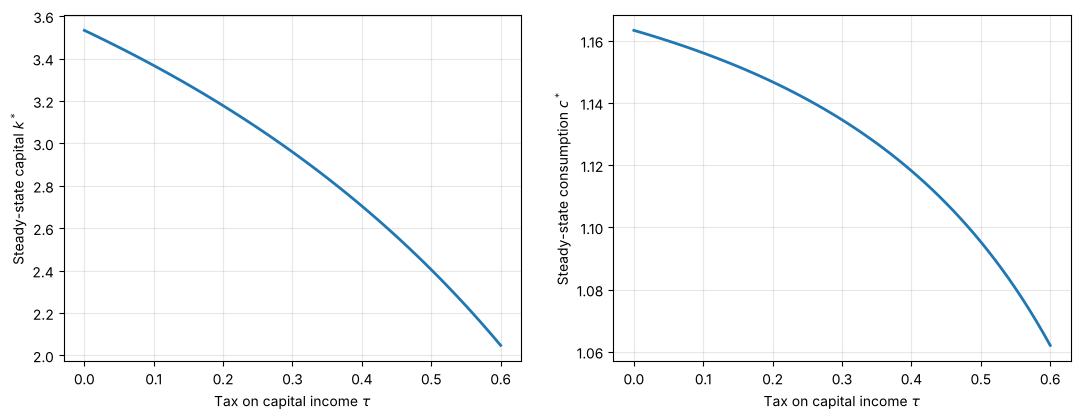

tau = 0.0:  k* = 3.5329,  c* = 1.1634
tau = 0.3:  k* = 2.9592,  c* = 1.1346


In [33]:
def steady_state_tax(tau, par):
    """Steady state of the Ramsey economy with a tax tau on capital income."""
    R_tau = par["delta"] + (1 / par["beta"] - 1) / (1 - tau)
    k = (par["alpha"] * par["A"] / R_tau)**(1 / (1 - par["alpha"]))
    c = f(k, par) - par["delta"] * k
    return k, c

taus = np.linspace(0, 0.6, 61)
k_tau, c_tau = steady_state_tax(taus, par)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(taus, k_tau, linewidth=2)
axes[0].set_xlabel(r"Tax on capital income $\tau$")
axes[0].set_ylabel(r"Steady-state capital $k^*$")
axes[0].grid(alpha=0.3)
axes[1].plot(taus, c_tau, linewidth=2)
axes[1].set_xlabel(r"Tax on capital income $\tau$")
axes[1].set_ylabel(r"Steady-state consumption $c^*$")
axes[1].grid(alpha=0.3)
plt.show()

k_old, c_old = steady_state_tax(0.0, par)
k_new, c_new = steady_state_tax(0.3, par)
print(f"tau = 0.0:  k* = {k_old:.4f},  c* = {c_old:.4f}")
print(f"tau = 0.3:  k* = {k_new:.4f},  c* = {c_new:.4f}")

### 13.2 The transition after a surprise reform

Suppose the economy is at its steady state without taxes and, at $t = 0$, the government introduces $\tau = 0.3$ by surprise. Capital is given at $k_0 = k^*(0)$, and the household chooses a new $c_0$. We need shooting again, with the after-tax Euler equation. As in Section 11, we copy the functions and change only the lines marked `# NEW`.

In [34]:
def consumption_growth_tax(k_next, par, tau):
    """Euler equation with the after-tax return on capital."""
    after_tax_return = 1 + (1 - tau) * (f_prime(k_next, par) - par["delta"])    # NEW
    return (par["beta"] * after_tax_return)**(1 / par["sigma"])


def simulate_tax(c0, k0, par, T, tau):
    """Ramsey system with a tax tau on capital income, rebated lump-sum."""
    k = np.zeros(T + 1)
    c = np.zeros(T + 1)
    k[0] = k0
    c[0] = c0
    status = "still running"

    for t in range(T):
        k[t + 1] = f(k[t], par) + (1 - par["delta"]) * k[t] - c[t]
        if k[t + 1] <= 0:
            status = "too high"
            break
        c[t + 1] = c[t] * consumption_growth_tax(k[t + 1], par, tau)            # NEW
        if k[t + 1] > 2 * k_gold:
            status = "too low"
            break

    return k[: t + 2], c[: t + 2], status


def shoot_tax(k0, par, T, tau, c_lo, c_hi, tol=1e-10, max_iter=200):
    """Shooting with a tax on capital income."""
    iteration = 0
    while (c_hi - c_lo) > tol and iteration < max_iter:
        c_mid = 0.5 * (c_lo + c_hi)
        k, c, status = simulate_tax(c_mid, k0, par, T, tau)                    # NEW
        if status == "too high":
            c_hi = c_mid
        else:
            c_lo = c_mid
        iteration = iteration + 1
    return 0.5 * (c_lo + c_hi)

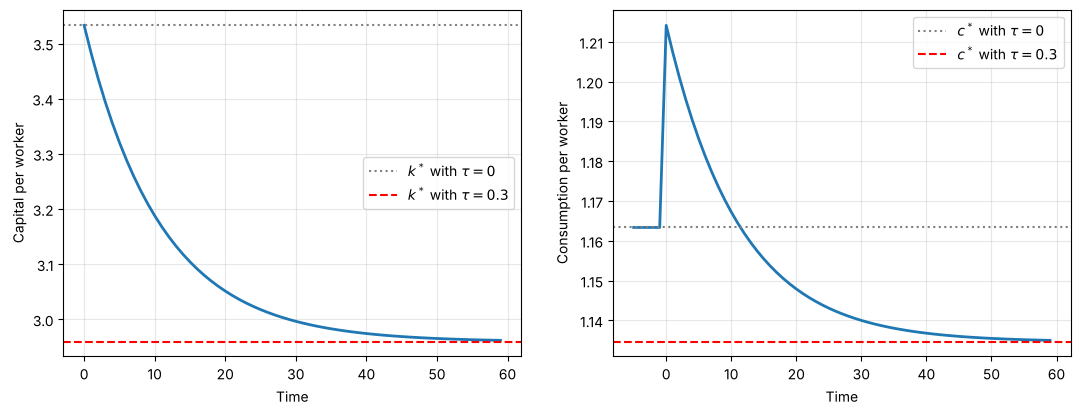

Consumption: 1.1634 before the reform, 1.2141 at t = 0, 1.1346 in the new steady state


In [35]:
tau = 0.3
T = 200
c_hi = f(k_old, par) + (1 - par["delta"]) * k_old      # consuming everything: too high

c0_tax = shoot_tax(k_old, par, T, tau, c_lo=0.0, c_hi=c_hi)
k_tax, c_tax, _ = simulate_tax(c0_tax, k_old, par, T, tau)

n_show = 60
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(k_tax[:n_show], linewidth=2)
axes[0].axhline(k_old, color="gray", linestyle=":", label=r"$k^*$ with $\tau = 0$")
axes[0].axhline(k_new, color="red", linestyle="--", label=r"$k^*$ with $\tau = 0.3$")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Capital per worker")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(np.arange(-5, n_show), np.concatenate([np.full(5, c_old), c_tax[:n_show]]), linewidth=2)
axes[1].axhline(c_old, color="gray", linestyle=":", label=r"$c^*$ with $\tau = 0$")
axes[1].axhline(c_new, color="red", linestyle="--", label=r"$c^*$ with $\tau = 0.3$")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Consumption per worker")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.show()

print(f"Consumption: {c_old:.4f} before the reform, {c0_tax:.4f} at t = 0, {c_new:.4f} in the new steady state")

In the right panel we added five periods before the reform, at the old consumption level, so that the jump is visible. To glue the two pieces together we used `np.concatenate([a, b])`, which puts array `b` after array `a`.

The reform produces a **consumption boom**. The tax lowers the return to saving, so the household saves less: consumption jumps up at $t = 0$ and capital starts to fall. As capital falls, output falls, and consumption declines gradually to a new steady state that is **lower** than the original one. The household eats part of its capital stock.

## 14. How much does the tax cost? A consumption-equivalent measure

### 14.1 Comparing steady states

The easiest calculation compares the two steady states. In a steady state consumption is constant, so the consumption equivalent is simply the ratio of the two consumption levels.

In [36]:
lam_ss = c_new / c_old - 1
print(f"Steady-state comparison: the tax is equivalent to changing consumption by {lam_ss:.2%} every period")

Steady-state comparison: the tax is equivalent to changing consumption by -2.47% every period


### 14.2 Including the transition

The steady-state comparison ignores the boom: the first generations of the reform consume **more**, not less. A proper well-being analysis compares the whole path after the reform with the status quo, staying at $c^*(0)$ forever, whose welfare is simply $u(c^*)/(1-\beta)$.

In [37]:
W_status_quo = utility(c_old, par["sigma"]) / (1 - par["beta"])
W_reform = welfare_infinite(c_tax[:100], par["beta"], par["sigma"])      # the periods we trust

lam_full = consumption_equivalent(W_reform, W_status_quo, par["sigma"])
print(f"Steady-state comparison : {lam_ss:.2%}")
print(f"Including the transition: {lam_full:.2%}")

Steady-state comparison : -2.47%
Including the transition: -0.27%


Including the transition, the cost is about **one tenth** of what the steady-state comparison suggests. The steady state is reached only after decades, and the household does not care much about decades from now: it discounts them with $\beta^t$. Meanwhile, the boom of the first periods counts almost fully.

This is the most important lesson of this section, and it goes well beyond this model: **comparing steady states is not a welfare analysis.** It tells us where the economy ends up, not how the people living through the change fare.

### 14.3 The cost for different tax rates

To finish, we repeat both calculations for a range of tax rates. A new tool: `enumerate(taus)` gives, in each pass of the loop, both the **position** `i` and the **value** `tau`, so we can store each result in position `i` of an array that we preallocated with `np.zeros`.

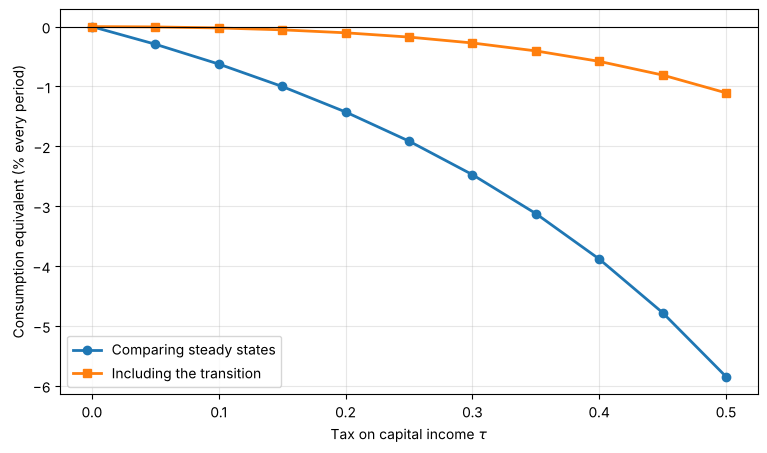

In [38]:
taus = np.linspace(0, 0.5, 11)
lam_ss_grid = np.zeros(len(taus))
lam_full_grid = np.zeros(len(taus))

for i, tau in enumerate(taus):
    k_new_i, c_new_i = steady_state_tax(tau, par)
    lam_ss_grid[i] = c_new_i / c_old - 1

    c0_i = shoot_tax(k_old, par, T, tau, c_lo=0.0, c_hi=c_hi)
    k_i, c_i, _ = simulate_tax(c0_i, k_old, par, T, tau)
    W_i = welfare_infinite(c_i[:100], par["beta"], par["sigma"])
    lam_full_grid[i] = consumption_equivalent(W_i, W_status_quo, par["sigma"])

plt.figure(figsize=(9, 5))
plt.plot(taus, 100 * lam_ss_grid, "o-", linewidth=2, label="Comparing steady states")
plt.plot(taus, 100 * lam_full_grid, "s-", linewidth=2, label="Including the transition")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel(r"Tax on capital income $\tau$")
plt.ylabel("Consumption equivalent (% every period)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Both measures say that the tax has a cost and that the cost grows faster than the tax rate: doubling $\tau$ more than doubles the loss. But the size of the loss depends crucially on whether we account for the transition.

## 15. Activity: a hypothetical reform

The numbers in this activity are illustrative; they are not an estimate for any particular country.

Suppose the economy already taxes capital income at $\tau = 0.20$ and a reform raises the rate to $\tau = 0.30$.

1. Starting from the steady state with $\tau = 0.20$, compute the transition after a surprise reform and plot capital and consumption.
2. Compute the cost of the reform comparing steady states and including the transition. Is the ratio between the two similar to the one in Section 14.2?
3. Repeat the calculation with $\sigma = 1$ and with $\sigma = 5$. How does $\sigma$ change the speed of the transition? And the cost? Remember the reading of $1/\sigma$ in Section 5.3.
4. **Challenge.** Suppose the reform is announced at $t = 0$ but takes effect at $t_1 = 10$. Combine what you did in Sections 11 and 13: the tax becomes an array `tau_path`, and the Euler equation of period $t$ uses `tau_path[t + 1]`. What does consumption do between $0$ and $t_1$?

Hint for item 3: to change a parameter without overwriting the original dictionary, create a copy with `par_new = par.copy()` and then modify `par_new["sigma"]`. If you write `par_new = par` instead, Python does **not** copy anything: both names point to the same dictionary, and changing one changes the other.

In [39]:
# Your code for the activity starts here.
# Step 1: steady state with tau = 0.20 (use steady_state_tax)

# Step 2: shooting from that steady state with tau = 0.30 (use shoot_tax and simulate_tax)

# Step 3: consumption equivalents (use welfare_infinite and consumption_equivalent)


## 16. Summary of Part II and what comes next

| Economics | Python |
|---|---|
| Households, firms and prices; the first welfare theorem | shifted slices `k[1:]` and `k[:-1]` |
| A tax on capital income as a wedge in the Euler equation | functions that return two values |
| The transition after a reform: a consumption boom | `np.concatenate` |
| Welfare costs: steady states versus full transitions | `enumerate`, filling preallocated arrays, `par.copy()` |

Ramsey gave us a household that chooses, and with it a way to rank policies by how much people gain or lose. But it has a strong assumption built in: one household that lives forever and cares about every future period. In the next block we drop it. In the **overlapping generations** model people live a finite number of periods, and new people are born every period. We will see that the market can then be **inefficient**, that the economy can save too much, and that a pension system can make every generation better off.